<a href="https://colab.research.google.com/github/ClaudioSeveroo/ciencia_de_dados/blob/main/aula11exercicios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dados = {
    "Mes": ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"],
    "Notebook": [20, 25, 22, 30, 35, 40],
    "Mouse": [50, 55, 48, 60, 65, 70],
    "Teclado": [30, 28, 35, 40, 38, 45]
}

df = pd.DataFrame(dados)
print(df)

   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38
5  Jun        40     70       45


In [13]:
print("\nPRIMEIRAS LINHAS:")
print(df.head())

print("\nDIMENSÕES DO DATAFRAME:")
print(df.shape)

print("\nESTATÍSTICAS DESCRITIVAS:")
print(df.describe())

# Seleciona apenas as colunas numéricas
produtos = ["Notebook", "Mouse", "Teclado"]
vendas = df[produtos]


PRIMEIRAS LINHAS:
   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38

DIMENSÕES DO DATAFRAME:
(6, 4)

ESTATÍSTICAS DESCRITIVAS:
        Notebook      Mouse    Teclado
count   6.000000   6.000000   6.000000
mean   28.666667  58.000000  36.000000
std     7.788881   8.602325   6.356099
min    20.000000  48.000000  28.000000
25%    22.750000  51.250000  31.250000
50%    27.500000  57.500000  36.500000
75%    33.750000  63.750000  39.500000
max    40.000000  70.000000  45.000000


In [14]:
print("\nINDICADORES DE VENDAS:")

for produto in produtos:
    valores = vendas[produto].to_numpy()

    media = np.mean(valores)
    maior = np.max(valores)
    menor = np.min(valores)
    total = np.sum(valores)

    print(f"\nProduto: {produto}")
    print(f"Média mensal: {media:.2f}")
    print(f"Maior venda mensal: {maior}")
    print(f"Menor venda mensal: {menor}")
    print(f"Total vendido: {total}")


INDICADORES DE VENDAS:

Produto: Notebook
Média mensal: 28.67
Maior venda mensal: 40
Menor venda mensal: 20
Total vendido: 172

Produto: Mouse
Média mensal: 58.00
Maior venda mensal: 70
Menor venda mensal: 48
Total vendido: 348

Produto: Teclado
Média mensal: 36.00
Maior venda mensal: 45
Menor venda mensal: 28
Total vendido: 216


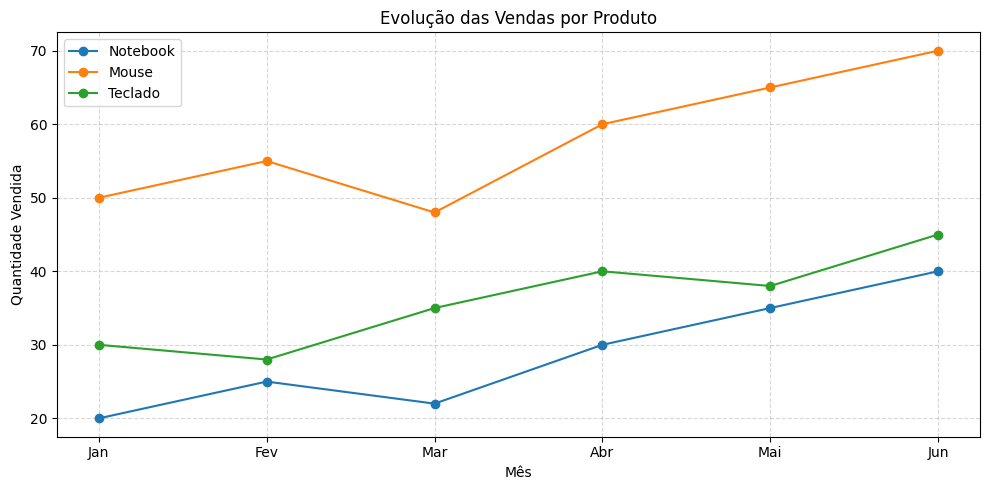

In [15]:
plt.figure(figsize=(10, 5))

for produto in produtos:
    plt.plot(
        df["Mes"],
        df[produto],
        marker="o",
        label=produto
    )

plt.title("Evolução das Vendas por Produto")
plt.xlabel("Mês")
plt.ylabel("Quantidade Vendida")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

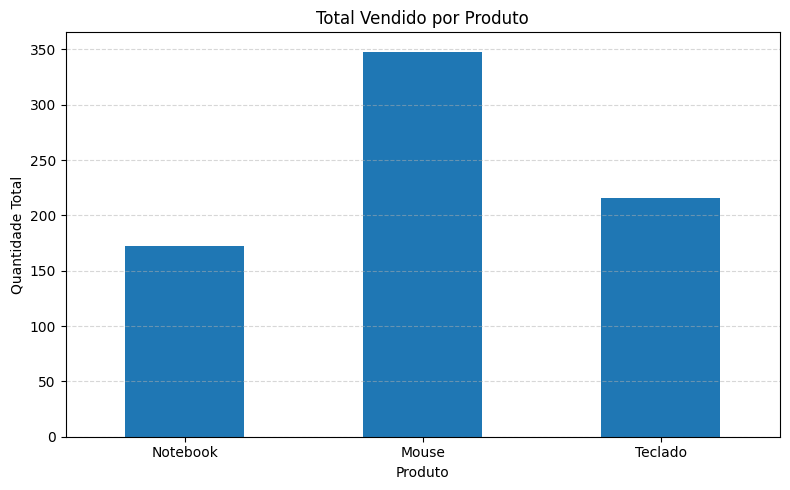

In [16]:
totais = vendas.sum()

plt.figure(figsize=(8, 5))
totais.plot(kind="bar")

plt.title("Total Vendido por Produto")
plt.xlabel("Produto")
plt.ylabel("Quantidade Total")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


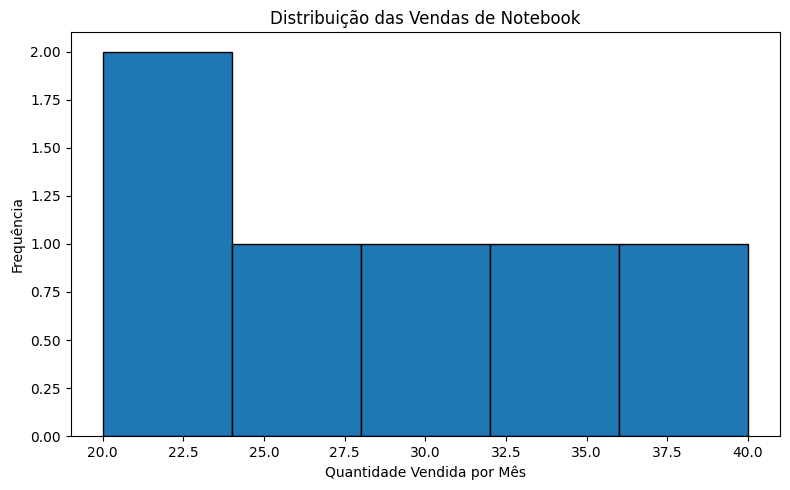

In [17]:
produto_escolhido = "Notebook"

plt.figure(figsize=(8, 5))
plt.hist(
    df[produto_escolhido],
    bins=5,
    edgecolor="black"
)

plt.title(f"Distribuição das Vendas de {produto_escolhido}")
plt.xlabel("Quantidade Vendida por Mês")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()

In [18]:
print("\nINTERPRETAÇÃO DOS RESULTADOS:")

produto_lider = totais.idxmax()

print(
    f"Produto com maior volume total: {produto_lider} "
    f"({totais[produto_lider]} unidades)"
)

for produto in produtos:
    indice_maximo = df[produto].idxmax()
    mes_maximo = df.loc[indice_maximo, "Mes"]
    valor_maximo = df.loc[indice_maximo, produto]

    print(
        f"{produto}: maior venda em {mes_maximo}, "
        f"com {valor_maximo} unidades."
    )



INTERPRETAÇÃO DOS RESULTADOS:
Produto com maior volume total: Mouse (348 unidades)
Notebook: maior venda em Jun, com 40 unidades.
Mouse: maior venda em Jun, com 70 unidades.
Teclado: maior venda em Jun, com 45 unidades.



VARIAÇÃO PERCENTUAL DAS VENDAS DE NOTEBOOKS:
0      NaN
1    25.00
2   -12.00
3    36.36
4    16.67
5    14.29
Name: Notebook, dtype: float64


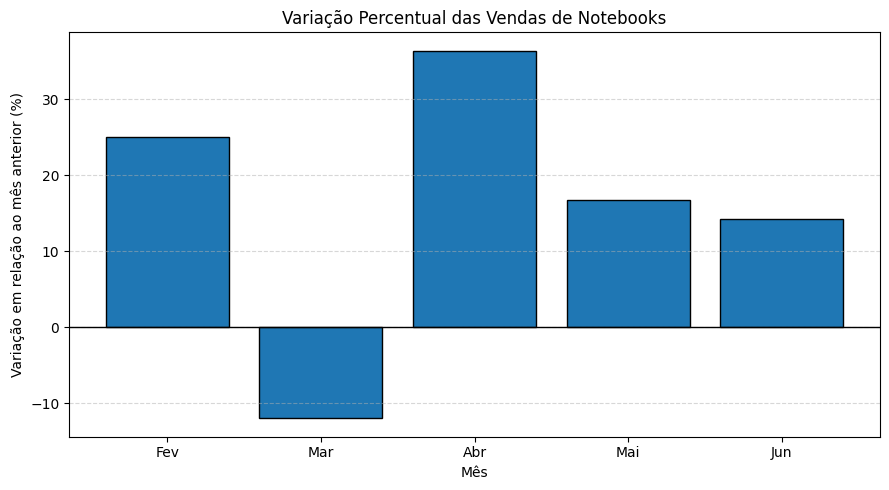

In [19]:
variacao = df["Notebook"].pct_change() * 100

print("\nVARIAÇÃO PERCENTUAL DAS VENDAS DE NOTEBOOKS:")
print(variacao.round(2))

plt.figure(figsize=(9, 5))
plt.bar(df["Mes"], variacao, edgecolor="black")

plt.axhline(0, color="black", linewidth=1)
plt.title("Variação Percentual das Vendas de Notebooks")
plt.xlabel("Mês")
plt.ylabel("Variação em relação ao mês anterior (%)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()